# C2 — Monthly customer purchase profiles
**Moisés Medina and Ignacia Castillo · Business Intelligence IIB423T-1 · 8 November 2026**

**Route: descriptive clustering.** Our question is: **can monthly purchase frequency and invoice size distinguish useful customer profiles beyond a simple value-only grouping rule?** We propose using those profiles for an analyst's month-end account review, while keeping unidentified purchase value visible. This is a proposed decision aid, not the retailer's documented strategy or a forecast.

W2 found concentration among identified customers, but a value ranking does not explain whether an account contributes through more invoices or larger invoices. We train one KMeans model and compare it with one simple value grouping rule. There are no known target labels and no classification accuracy, churn prediction or claimed intervention effect.

## 1. W2 feedback and delivery correction

The actual W2 feedback reported missing **received executable evidence**: the notebook, sample identifiers, subsets, preprocessing/gate implementation and repository version links. The corrected W2 repository now exposes those files. For C2, **all functions needed below are visible inside this notebook**. We submit the executed notebook, a brief of at most three pages and an editable presentation in one ZIP, without data or environment folders, as the updated C2 brief requires.

The instructor also asked for later-period/cohort evidence and a separate unidentified-value category. Section 7 follows an earlier fixed review group into October–November and reports unidentified value separately. These historical months were already explored in W1/C1/W2, so they are not pristine prospective evidence.

## 2. Reproducible source and setup

Source: Chen (2015), **UCI Online Retail**, DOI 10.24432/C5BW33, CC BY 4.0. The original XLSX has 541,909 invoice lines from 1 December 2010 to 9 December 2011. We reuse W2's unchanged **516,384-line complete-month extract**, excluding only partial December 2011. A SHA-256 check verifies the extract. When the local project input is unavailable, this notebook downloads that exact public extract from an immutable repository commit. No dataset is embedded in the submission ZIP. Saved outputs remain readable without rerunning or network access.

The analysis used Python 3.12.5, numpy 2.1.0, pandas 2.2.2, matplotlib 3.9.2 and scikit-learn 1.5.2. All project code is inline. To rerun in a suitable Python/Jupyter environment, run cells in order; no new environment or installation package is required by the brief.

In [1]:
"""C2 clustering analysis. These functions are embedded in full in the submitted notebook."""
from pathlib import Path
from io import BytesIO
import hashlib
import json
import math
import urllib.request

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

SEED = 4232026
RAW_SHA = '8f6d42748e36cf41008f411307fe77e03b2001d25eb445dcfab5aa70186fdb4f'
RAW_URL = ('https://raw.githubusercontent.com/DirtyCheese02/online-retail-bi-medina-castillo/'
           'e19b529d84144f2089d43fceede8aba73e2fc315/data/raw/online_retail_2010dec_2011nov_input.csv')
FEATURES = ['invoices', 'mean_invoice_value_gbp']
SPLITS = {'train': ('2010-12-01', '2011-08-01'),
          'validation': ('2011-08-01', '2011-10-01'),
          'test': ('2011-10-01', '2011-12-01')}
from IPython.display import display, Markdown, Image
import platform, sklearn
pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',110)
OUT=Path.cwd()/'outputs'
OUT.mkdir(exist_ok=True)
print('Python:',platform.python_version(),'scikit-learn:',sklearn.__version__)
print('Seed:',SEED,'Model: KMeans(k=3, n_init=20, max_iter=300, algorithm=lloyd)')
print('Preparation and windows remain fixed from W2. Model choices are fixed before the results below.')

Python: 3.12.5 scikit-learn: 1.5.2
Seed: 4232026 Model: KMeans(k=3, n_init=20, max_iter=300, algorithm=lloyd)
Preparation and windows remain fixed from W2. Model choices are fixed before the results below.


### What one source line means

One row is one **item entry on an invoice**. Several lines can form one invoice, and a CustomerID can link several invoices. The eight source fields are:

| Function | Original fields | Interpretation |
|---|---|---|
| Invoice and item keys | InvoiceNo, StockCode, Description | A C-prefixed invoice is a cancellation record; StockCode is not a verified commercial category. |
| Recorded activity | Quantity, InvoiceDate, UnitPrice | Signed units, recorded timestamp and unit price in GBP. |
| Customer context | CustomerID, Country | Account identifier and the country label on that source line. |

**The model uses a different unit:** one *active identified customer in one calendar month*. For example, a customer with two eligible invoices totalling £100 has frequency 2 and mean invoice value £50 for that month. This example explains the aggregation; it is not an asserted source record.

In [2]:
def load_source(force_download=False):
    candidates = [p / 'data/raw/online_retail_2010dec_2011nov_input.csv'
                  for p in [Path.cwd(), *Path.cwd().parents]]
    local = next((p for p in candidates if p.is_file()), None)
    if local is not None and not force_download:
        payload = local.read_bytes(); origin = 'Preserved local W2 extract'
    else:
        with urllib.request.urlopen(RAW_URL, timeout=60) as response:
            payload = response.read()
        origin = 'Pinned public W2 extract downloaded; no dataset included in ZIP'
    assert hashlib.sha256(payload).hexdigest() == RAW_SHA
    raw = pd.read_csv(BytesIO(payload), dtype={'InvoiceNo': 'string', 'StockCode': 'string',
            'CustomerID': 'Int64', 'Description': 'string', 'Country': 'string'}, parse_dates=['InvoiceDate'])
    assert len(raw) == 516384 and len(raw.columns) == 8
    d = raw.copy(); d.insert(0, 'source_row', np.arange(1, len(d) + 1))
    d['month'] = d.InvoiceDate.dt.strftime('%Y-%m')
    d['c_record'] = d.InvoiceNo.str.startswith('C')
    d['merchandise'] = d.StockCode.str.fullmatch('[0-9]{5}[A-Z]?')
    d['eligible'] = d.merchandise & ~d.c_record & d.Quantity.gt(0) & d.UnitPrice.gt(0)
    d['eligible_c'] = d.merchandise & d.c_record & d.Quantity.lt(0) & d.UnitPrice.gt(0)
    d['row_group'] = np.select([d.eligible, d.eligible_c], ['purchase', 'C_record'], default='other_retained')
    d['value_gbp'] = np.where(d.eligible, d.Quantity * d.UnitPrice, np.nan)
    d['split'] = ''
    for name, (start, end) in SPLITS.items():
        d.loc[d.InvoiceDate.ge(start) & d.InvoiceDate.lt(end), 'split'] = name
    return d, {'origin': origin, 'input_sha256': RAW_SHA, 'source_rows': len(raw), 'source_columns': 8}

def check_preparation(d):
    checks = []
    def record(name, n, treatment, structural=False):
        if structural: assert n == 0, name
        checks.append({'check': name, 'affected': int(n), 'status': 'PASS' if n == 0 else 'FLAG', 'treatment': treatment})
    record('Missing/outside-window timestamps', (d.InvoiceDate.isna() | d.split.eq('')).sum(), 'Stop on invalid partition date', True)
    record('Missing invoice/item keys', (d.InvoiceNo.isna() | d.StockCode.isna()).sum(), 'Stop; grouping requires keys', True)
    record('Missing customer IDs', d.CustomerID.isna().sum(), 'Keep eligible value; exclude both customer grouping methods')
    record('Nonpositive prices', d.UnitPrice.le(0).sum(), 'Keep source; exclude purchase measure; no imputation')
    record('Negative quantity without C', (d.Quantity.lt(0) & ~d.c_record).sum(), 'Keep outside purchase and eligible cancellation measures')
    record('Outside provisional item pattern', (~d.merchandise).sum(), 'Keep source; exclude scoped measure; pattern is not verified category')
    record('Missing descriptions', d.Description.isna().sum(), 'Do not remove solely for description; use StockCode')
    original = ['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID','Country']
    record('Exact repeats beyond first copy', d.duplicated(original).sum(), 'Retain W2 baseline; no unique line ID proves error')
    record('Invoices crossing partitions', d.groupby('InvoiceNo').split.nunique().gt(1).sum(), 'Stop to avoid sibling-line leakage', True)
    record('Known IDs shared within one eligible invoice', d.loc[d.eligible].groupby('InvoiceNo').CustomerID.nunique().gt(1).sum(), 'Stop before customer aggregate', True)
    record('Source-row loss or repeated source position', int(len(d) != 516384 or not d.source_row.is_unique), 'Conserve every original row', True)
    assert int(d.eligible.sum()) == 500531 and int(d.eligible_c.sum()) == 8351
    counts = d.row_group.value_counts().rename_axis('group').reset_index(name='source_rows')
    summary = d.groupby('split', sort=False).agg(source_rows=('source_row','size'), invoices=('InvoiceNo','nunique'), known_ids_raw=('CustomerID','nunique'))
    summary = summary.reindex(['train','validation','test']).reset_index()
    assert summary.source_rows.tolist() == [285421,85510,145453]
    return pd.DataFrame(checks), counts, summary
data,source_info=load_source()
quality,row_flow,source_partitions=check_preparation(data)
display(pd.DataFrame([source_info]))
display(quality)
display(row_flow)
display(source_partitions)
display(data[['InvoiceNo','StockCode','Quantity','InvoiceDate','UnitPrice','CustomerID','Country']].head(3))

,origin,input_sha256,source_rows,source_columns
0,Pinned public W2 extract downloaded; no dataset included in ZIP,8f6d42748e36cf41008f411307fe77e03b2001d25eb445dcfab5aa70186fdb4f,516384,8


,check,affected,status,treatment
0,Missing/outside-window timestamps,0,PASS,Stop on invalid partition date
1,Missing invoice/item keys,0,PASS,Stop; grouping requires keys
2,Missing customer IDs,127216,FLAG,Keep eligible value; exclude both customer grouping methods
3,Nonpositive prices,2463,FLAG,Keep source; exclude purchase measure; no imputation
4,Negative quantity without C,1306,FLAG,Keep outside purchase and eligible cancellation measures
5,Outside provisional item pattern,5072,FLAG,Keep source; exclude scoped measure; pattern is not verified category
6,Missing descriptions,1439,FLAG,Do not remove solely for description; use StockCode
7,Exact repeats beyond first copy,4989,FLAG,Retain W2 baseline; no unique line ID proves error
8,Invoices crossing partitions,0,PASS,Stop to avoid sibling-line leakage
9,Known IDs shared within one eligible invoice,0,PASS,Stop before customer aggregate


,group,source_rows
0,purchase,500531
1,C_record,8351
2,other_retained,7502


,split,source_rows,invoices,known_ids_raw
0,train,285421,14722,3193
1,validation,85510,4064,1817
2,test,145453,6099,2446


,InvoiceNo,StockCode,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,8,2010-12-01 08:26:00,2.75,17850,United Kingdom


### Why the eligibility rules remain

An eligible purchase has positive quantity/price, a non-C invoice and a provisional StockCode pattern of five digits with an optional final letter. Value is `Quantity × UnitPrice` in GBP. We retain every source line and distinguish purchases, eligible C records and other retained lines. Only scoped positive purchases enter the value measure.

- Missing CustomerID: retain its eligible value in coverage, but neither grouping method can assign a profile to an unknown identity.
- Zero/negative prices or quantities: retain the source entry outside the positive-purchase measure. We do not invent a discount explanation or fill prices with another month.
- Exact repeats: retain W2's baseline because no unique line ID proves them erroneous.
- Missing descriptions: do not exclude solely for description; the recorded item key is StockCode.
- Code-pattern exceptions: retain the source record and disclose the provisional scope. This pattern is not a verified product taxonomy.

These rules reproduce W2's 500,531 eligible purchase lines and 4,293 annual known IDs. The descriptive value is not audited net revenue, profit, loyalty or lifetime value.

## 3. Modeling records, features and chronological partitions

We aggregate eligible identified lines into invoices, then invoices into **CustomerID-month** records. Months without an eligible identified purchase do not become artificial zeros. The target population here is the *observed purchase-active identified account-months*, not all retailer customers or all real purchases. A customer may occur in several months and can have different profiles over time.

| Feature | Definition and unit | Why include it? |
|---|---|---|
| `invoices` | Distinct eligible InvoiceNo count per ID-month | Describes purchase frequency in the observed month. |
| `mean_invoice_value_gbp` | Eligible monthly value / invoice count, GBP per invoice | Distinguishes larger invoices from more frequent ones. |

Monthly value equals frequency × mean invoice value. We report it for business interpretation and the reference rule; adding it as a third clustering feature would repeat the same information. CustomerID and country never enter the distance calculation. A completed calendar month is the business review window; month lengths and activity still differ.

We reuse W2 dates: **train December–July; validation August–September; test October–November**. Test is reserved first; validation is drawn from the earlier development period. No invoice or ID-month crosses a partition. Recurrent CustomerIDs are allowed for a same-account temporal review and do not establish independent new-customer generalization.

In [3]:
def monthly_records(d):
    p = d.loc[d.eligible & d.CustomerID.notna()].copy()
    invoice = p.groupby(['split','month','CustomerID','InvoiceNo'], observed=True).agg(
        invoice_value_gbp=('value_gbp','sum'), first=('InvoiceDate','min'), last=('InvoiceDate','max')).reset_index()
    m = invoice.groupby(['split','month','CustomerID'], observed=True).agg(
        invoices=('InvoiceNo','nunique'), monthly_value_gbp=('invoice_value_gbp','sum'),
        first_invoice=('first','min'), last_invoice=('last','max')).reset_index()
    m['mean_invoice_value_gbp'] = m.monthly_value_gbp / m.invoices
    assert not m.duplicated(['month','CustomerID']).any()
    assert m[FEATURES].gt(0).all().all() and np.isfinite(m[FEATURES].to_numpy()).all()
    assert np.allclose(m.monthly_value_gbp, m.invoices * m.mean_invoice_value_gbp)
    parts = {name: m.loc[m.split.eq(name)].copy().reset_index(drop=True) for name in SPLITS}
    for name, (start,end) in SPLITS.items():
        assert parts[name].first_invoice.ge(start).all() and parts[name].last_invoice.lt(end).all()
    return m, parts
monthly,parts=monthly_records(data)
model_partitions=pd.DataFrame([{'split':k,'active_ID_months':len(v),'unique_active_IDs':v.CustomerID.nunique(),'months':v.month.nunique()} for k,v in parts.items()])
display(model_partitions)
overlap_rows=[]
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    keys_a=set(zip(parts[a].month,parts[a].CustomerID));keys_b=set(zip(parts[b].month,parts[b].CustomerID))
    assert not(keys_a & keys_b)
    overlap_rows.append({'left':a,'right':b,'shared_ID_months':len(keys_a & keys_b),
                         'shared_CustomerIDs':len(set(parts[a].CustomerID)&set(parts[b].CustomerID))})
display(pd.DataFrame(overlap_rows))
display(parts['train'][['month','CustomerID',*FEATURES,'monthly_value_gbp']].head())

,split,active_ID_months,unique_active_IDs,months
0,train,7195,3145,8
1,validation,2192,1769,2
2,test,3021,2405,2


,left,right,shared_ID_months,shared_CustomerIDs
0,train,validation,0,1301
1,train,test,0,1532
2,validation,test,0,1096


,month,CustomerID,invoices,mean_invoice_value_gbp,monthly_value_gbp
0,2010-12,12347,1,711.79,711.79
1,2010-12,12348,1,652.80,652.80
2,2010-12,12370,2,874.01,1748.02
3,2010-12,12377,1,1001.52,1001.52
4,2010-12,12383,1,555.72,555.72


## 4. One trained model and one reference

**KMeans** repeatedly assigns each record to its nearest center and updates the centers to minimize the sum of squared Euclidean distances. We fix **k=3**, seed 4232026, 20 initializations, at most 300 iterations and Lloyd updates. Three profiles are a manageable first description, not an empirically established optimal number. We do not search algorithms or k values.

Both inputs are positive and skewed. We apply `log1p` to reduce the influence of large ranges, then fit **StandardScaler only on training records** so GBP does not dominate invoice count. Large accounts remain in the data. Scaling changes distances and thus the meaning of similarity; it does not change GBP used for K10 or reporting. W2 demonstrated a scaler at invoice level. The actual C2 monthly features require a new training-only fit at their own unit.

**Reference:** a simple monthly-value rule. Learn the training 50th and 90th percentile cutoffs, then keep them fixed: lower, middle and higher recorded value. Its later-period proportions need not remain 50/40/10. It is a reference partition, not a set of true customer classes.

All features for an ID-month are available **after that month's close**. This is a retrospective grouping, not a before-purchase prediction. No information from future months enters an earlier record.

In [4]:
def fit_first_model(training):
    xlog = np.log1p(training[FEATURES].to_numpy(dtype=float))
    scaler = StandardScaler().fit(xlog)
    with threadpool_limits(limits=1):
        model = KMeans(n_clusters=3, n_init=20, max_iter=300, random_state=SEED, algorithm='lloyd').fit(scaler.transform(xlog))
    # Name only by training profiles, so a test result cannot choose label order.
    labelled = training.assign(raw_cluster=model.labels_)
    order = labelled.groupby('raw_cluster').monthly_value_gbp.median().sort_values().index.tolist()
    names = {int(raw): f'Profile {i+1}' for i,raw in enumerate(order)}
    cuts = np.quantile(training.monthly_value_gbp, [.5,.9])
    assert cuts[0] < cuts[1]
    frozen = {'feature_names': FEATURES, 'k':3, 'n_init':20, 'max_iter':300, 'seed':SEED,
              'fit_records':len(training), 'fit_months':sorted(training.month.unique().tolist()),
              'scaler_mean':scaler.mean_.tolist(), 'scaler_scale':scaler.scale_.tolist(),
              'cluster_centers':model.cluster_centers_.tolist(), 'cluster_names':names,
              'reference_p50_gbp':float(cuts[0]), 'reference_p90_gbp':float(cuts[1]),
              'test_used_for_model_choice':False, 'prior_full_case_exposure':True}
    return scaler, model, names, cuts, frozen

def parameters_unchanged(scaler, model, frozen):
    assert int(scaler.n_samples_seen_) == frozen['fit_records']
    assert np.array_equal(scaler.mean_, frozen['scaler_mean'])
    assert np.array_equal(scaler.scale_, frozen['scaler_scale'])
    assert np.array_equal(model.cluster_centers_, frozen['cluster_centers'])
scaler,model,cluster_names,cuts,frozen=fit_first_model(parts['train'])
frozen_fingerprint=hashlib.sha256(json.dumps(frozen,sort_keys=True).encode()).hexdigest()
display(pd.DataFrame({'feature':FEATURES,'training_log_mean':scaler.mean_,'training_log_SD':scaler.scale_}))
print('Training records used for fit:',scaler.n_samples_seen_)
print('Reference value cutoffs (GBP, exact):',cuts.tolist())
print('Frozen settings fingerprint:',frozen_fingerprint)
print('No fit is performed on validation or test.')

,feature,training_log_mean,training_log_SD
0,invoices,0.822860,0.278592
1,mean_invoice_value_gbp,5.644551,0.822984


Training records used for fit: 7195
Reference value cutoffs (GBP, exact): [329.65, 1036.7680000000007]
Frozen settings fingerprint: 944c70562aa51997cf6038aace2782464c8e9887f9fd59739e966715321182f7
No fit is performed on validation or test.


## 5. Validation before test

We inspect whether the fixed model and reference can assign every validation record, whether all groups are populated, and whether the learned parameters remain unchanged. A structural failure stops execution before test. We show the profiles and an internal separation diagnostic. We retain this first model without searching for a better validation/test score.

**Silhouette** compares each record's average distance within its assigned group with its nearest other group. Its range is approximately −1 to 1: larger values indicate clearer separation in the specified scaled feature space. We calculate both methods on the **same records and same transformed inputs**. It is not accuracy and there are no known class labels. KMeans optimizes a related distance objective, so a geometric advantage does not show better commercial outcomes.

In [5]:
def assess(frame, scaler, model, names, cuts, frozen, partition):
    x = scaler.transform(np.log1p(frame[FEATURES].to_numpy(dtype=float)))
    parameters_unchanged(scaler,model,frozen)
    with threadpool_limits(limits=1):
        labels = model.predict(x)
    grouped = frame.copy()
    grouped['cluster'] = [names[int(i)] for i in labels]
    grouped['reference'] = np.select([frame.monthly_value_gbp.le(cuts[0]), frame.monthly_value_gbp.le(cuts[1])],
                                     ['Lower value','Middle value'], default='Higher value')
    assert len(grouped) == len(frame) and not grouped[['cluster','reference']].isna().any().any()
    def profiles(col):
        g = grouped.groupby(col).agg(records=('CustomerID','size'), unique_ids=('CustomerID','nunique'),
            median_invoices=('invoices','median'), median_invoice_value_gbp=('mean_invoice_value_gbp','median'),
            median_monthly_value_gbp=('monthly_value_gbp','median'), eligible_value_gbp=('monthly_value_gbp','sum')).reset_index()
        g['record_share_pct'] = 100*g.records/len(frame)
        g['known_value_share_pct'] = 100*g.eligible_value_gbp/g.eligible_value_gbp.sum()
        g.insert(0,'partition',partition); g.insert(1,'method','KMeans' if col=='cluster' else 'Value rule')
        return g.rename(columns={col:'group'})
    metric_rows=[]
    for method,col in [('KMeans','cluster'),('Value rule','reference')]:
        with threadpool_limits(limits=1):
            score = float(silhouette_score(x,grouped[col])) if grouped[col].nunique()>1 else float('nan')
        metric_rows.append({'partition':partition,'method':method,'records':len(frame),'silhouette':score,
                            'populated_groups':grouped[col].nunique()})
    comparison = pd.crosstab(grouped.cluster,grouped.reference).reindex(
        index=['Profile 1','Profile 2','Profile 3'],columns=['Lower value','Middle value','Higher value'],fill_value=0)
    parameters_unchanged(scaler,model,frozen)
    return grouped, pd.concat([profiles('cluster'),profiles('reference')],ignore_index=True), pd.DataFrame(metric_rows), comparison

def validation_gate(validation_grouped, scaler, model, frozen):
    checks = {'finite_positive_features': bool(np.isfinite(validation_grouped[FEATURES]).all().all() and validation_grouped[FEATURES].gt(0).all().all()),
              'exactly_three_profiles_assigned': validation_grouped.cluster.nunique()==3,
              'all_records_have_both_groups': not validation_grouped[['cluster','reference']].isna().any().any(),
              'no_test_months_in_fit': max(frozen['fit_months']) < '2011-08',
              'validation_months_only': set(validation_grouped.month)=={'2011-08','2011-09'}}
    parameters_unchanged(scaler,model,frozen)
    checks['learned_parameters_unchanged'] = True
    assert all(checks.values()), checks
    return pd.DataFrame([{'validation_check':name,'passed':bool(value)} for name,value in checks.items()])
validation,validation_profiles,validation_metrics,validation_cross=assess(parts['validation'],scaler,model,cluster_names,cuts,frozen,'validation')
gate=validation_gate(validation,scaler,model,frozen)
display(validation_metrics)
display(validation_profiles[['method','group','records','record_share_pct','median_invoices','median_invoice_value_gbp','median_monthly_value_gbp']])
display(gate)
assert gate.passed.all()
parameters_unchanged(scaler,model,frozen)
assert hashlib.sha256(json.dumps(frozen,sort_keys=True).encode()).hexdigest()==frozen_fingerprint
print('Validation decision: keep the prespecified first model and reference. No refit or tuning follows.')

,partition,method,records,silhouette,populated_groups
0,validation,KMeans,2192,0.471703,3
1,validation,Value rule,2192,0.300424,3


,method,group,records,record_share_pct,median_invoices,median_invoice_value_gbp,median_monthly_value_gbp
0,KMeans,Profile 1,602,27.463504,1.0,148.960,153.10
1,KMeans,Profile 2,1173,53.512774,1.0,414.190,414.19
2,KMeans,Profile 3,417,19.023723,2.0,324.305,747.04
3,Value rule,Higher value,255,11.633212,2.0,1074.820,1565.55
4,Value rule,Lower value,999,45.574818,1.0,194.240,206.69
5,Value rule,Middle value,938,42.791971,1.0,429.555,514.65


,validation_check,passed
0,finite_positive_features,True
1,exactly_three_profiles_assigned,True
2,all_records_have_both_groups,True
3,no_test_months_in_fit,True
4,validation_months_only,True
5,learned_parameters_unchanged,True


Validation decision: keep the prespecified first model and reference. No refit or tuning follows.


## 6. Final test comparison on identical records

The settings, preprocessing and reference thresholds are now fixed. Test uses October–November active identified ID-months. We apply the unchanged transform and centers, then report group sizes, original-unit profiles and the reference comparison. Unique IDs within different groups can overlap across months, so **record counts, not sums of per-group unique IDs**, define the partition size.

In [6]:
assert gate.passed.all()
test,test_profiles,test_metrics,test_cross=assess(parts['test'],scaler,model,cluster_names,cuts,frozen,'test')
parameters_unchanged(scaler,model,frozen)
assert hashlib.sha256(json.dumps(frozen,sort_keys=True).encode()).hexdigest()==frozen_fingerprint
display(test_metrics)
display(test_profiles[['method','group','records','record_share_pct','median_invoices','median_invoice_value_gbp','median_monthly_value_gbp','known_value_share_pct']])
display(test_cross)
assert test_cross.to_numpy().sum()==len(test)
print('Test ID-month records:',len(test),'Distinct active IDs:',test.CustomerID.nunique())
print('All model/reference comparisons use these same records.')

,partition,method,records,silhouette,populated_groups
0,test,KMeans,3021,0.464083,3
1,test,Value rule,3021,0.289010,3


,method,group,records,record_share_pct,median_invoices,median_invoice_value_gbp,median_monthly_value_gbp,known_value_share_pct
0,KMeans,Profile 1,864,28.599801,1.0,152.480,155.305,6.170184
1,KMeans,Profile 2,1352,44.753393,1.0,416.190,416.190,38.825728
2,KMeans,Profile 3,805,26.646806,2.0,313.225,733.090,55.004088
3,Value rule,Higher value,380,12.578616,2.0,817.780,1526.365,53.174470
4,Value rule,Lower value,1357,44.918901,1.0,183.600,203.720,12.846314
5,Value rule,Middle value,1284,42.502483,1.0,409.260,517.050,33.979215


reference,Lower value,Middle value,Higher value
cluster,,,
Profile 1,864,0,0
Profile 2,405,823,124
Profile 3,88,461,256


Test ID-month records: 3021 Distinct active IDs: 2405
All model/reference comparisons use these same records.


### Interpretation of the first model

We describe Profile 1 as smaller-invoice months, Profile 2 as larger single-invoice months and Profile 3 as more frequent purchase months, based on the saved original-unit medians. These are descriptions of observed groups, not known customer types, proof of loyalty or permanent labels. The reference mostly answers how much value was recorded; the model separates frequency from invoice size. The cross-table shows where that distinction changes the description. Monthly value equals frequency times average invoice value for each record; separately calculated group medians need not satisfy that product identity.

## 7. W2 follow-up: fixed earlier accounts and unidentified value

For a separate business diagnostic, freeze the top decile of known IDs using December–September purchases only, then follow those same accounts in October and November. Contrast their share with each month's re-ranked top decile. Group sizes differ, so this is a persistence diagnostic rather than a like-for-like model contest. A previously important ID without a purchase in one later month is not proven to have churned.

We also split **all eligible purchase value** into purchases attributed to the current known-ID top group, other identified purchases and unidentified purchases. The last bucket may contain many real people; it is not an artificial customer or a cluster. K10 itself keeps the known-ID denominator. These later historical periods were already exposed in prior EDA and provide no evidence about current 2026 customers.

In [7]:
def concentration_followup(d):
    p = d.loc[d.eligible].copy()
    identified = p.dropna(subset=['CustomerID'])
    prior = identified.loc[identified.InvoiceDate.lt('2011-10-01')].groupby('CustomerID').value_gbp.sum().sort_values(ascending=False)
    frozen_ids = set(prior.head(math.ceil(.1*len(prior))).index)
    rows=[]; bridges=[]
    for month in ['2011-10','2011-11']:
        all_month = p.loc[p.month.eq(month)]
        known = all_month.dropna(subset=['CustomerID']).groupby('CustomerID').value_gbp.sum().sort_values(ascending=False)
        current_top = known.head(math.ceil(.1*len(known)))
        all_value=float(all_month.value_gbp.sum()); known_value=float(known.sum())
        frozen_value=float(known.loc[known.index.isin(frozen_ids)].sum())
        rows.append({'month':month,'active_known_ids':len(known),'reference_ids':len(prior),
            'frozen_review_ids':len(frozen_ids),'frozen_ids_active':int(known.index.isin(frozen_ids).sum()),
            'reranked_K10_pct':100*float(current_top.sum())/known_value,
            'frozen_group_known_value_pct':100*frozen_value/known_value,
            'frozen_group_all_value_pct':100*frozen_value/all_value,
            'ID_coverage_pct':100*known_value/all_value})
        bridges.append({'month':month,'Known top-decile purchases':100*float(current_top.sum())/all_value,
                        'Other identified purchases':100*(known_value-float(current_top.sum()))/all_value,
                        'Unidentified purchases':100*(all_value-known_value)/all_value})
    bridge=pd.DataFrame(bridges)
    assert np.allclose(bridge.iloc[:,1:].sum(axis=1),100)
    all_known=identified.groupby('CustomerID').value_gbp.sum().sort_values(ascending=False)
    annual={'known_ids':len(all_known),'K10_pct':100*all_known.head(math.ceil(.1*len(all_known))).sum()/all_known.sum(),
            'ID_coverage_pct':100*all_known.sum()/p.value_gbp.sum()}
    assert len(all_known)==4293 and np.isclose(annual['K10_pct'],60.50013933127034)
    return pd.DataFrame(rows),bridge,annual
stability,value_bridge,annual=concentration_followup(data)
display(pd.DataFrame([annual]))
display(stability)
display(value_bridge)
assert np.allclose(value_bridge.iloc[:,1:].sum(axis=1),100)
print('Annual W2 K10 and coverage reproduced; unidentified value remains separate.')

,known_ids,K10_pct,ID_coverage_pct
0,4293,60.500139,85.662768


,month,active_known_ids,reference_ids,frozen_review_ids,frozen_ids_active,reranked_K10_pct,frozen_group_known_value_pct,frozen_group_all_value_pct,ID_coverage_pct
0,2011-10,1361,3613,362,218,50.773290,48.161013,43.857017,91.063319
1,2011-11,1660,3613,362,265,47.794125,46.125135,36.231835,78.551173


,month,Known top-decile purchases,Other identified purchases,Unidentified purchases
0,2011-10,46.235843,44.827476,8.936681
1,2011-11,37.542846,41.008327,21.448827


Annual W2 K10 and coverage reproduced; unidentified value remains separate.


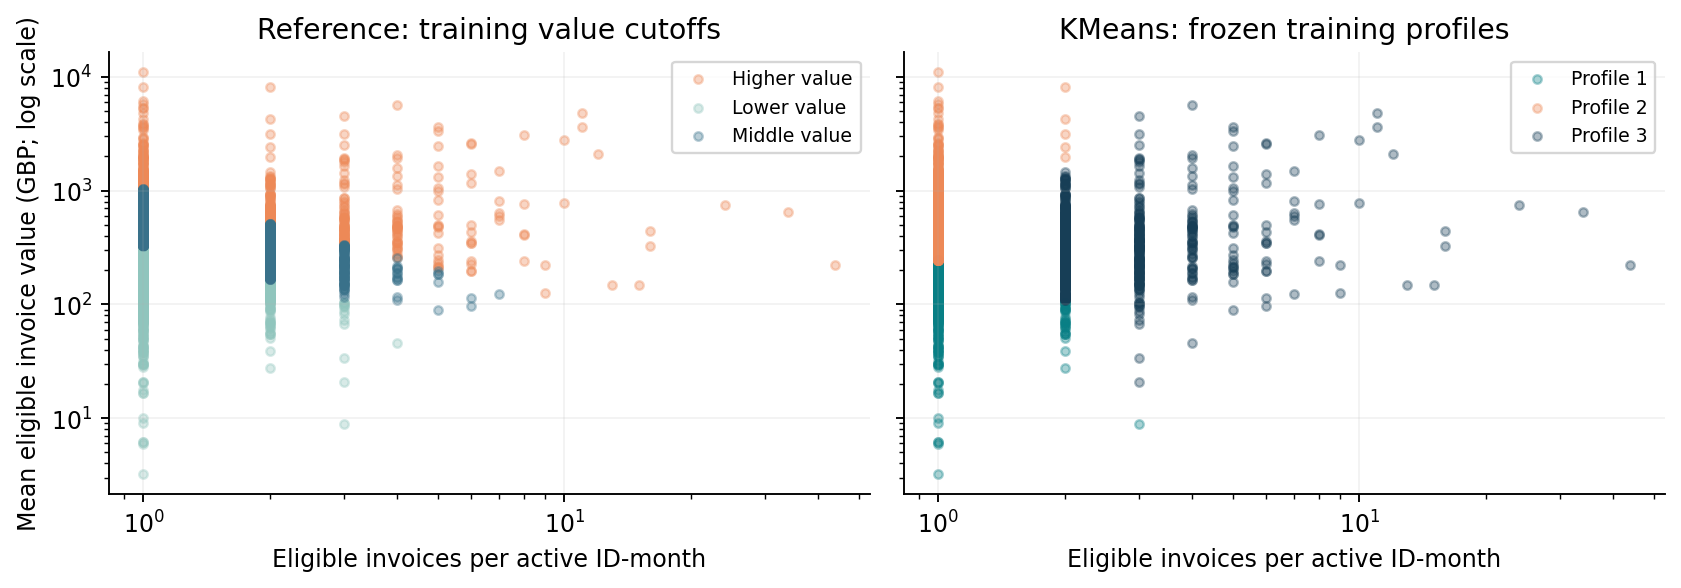

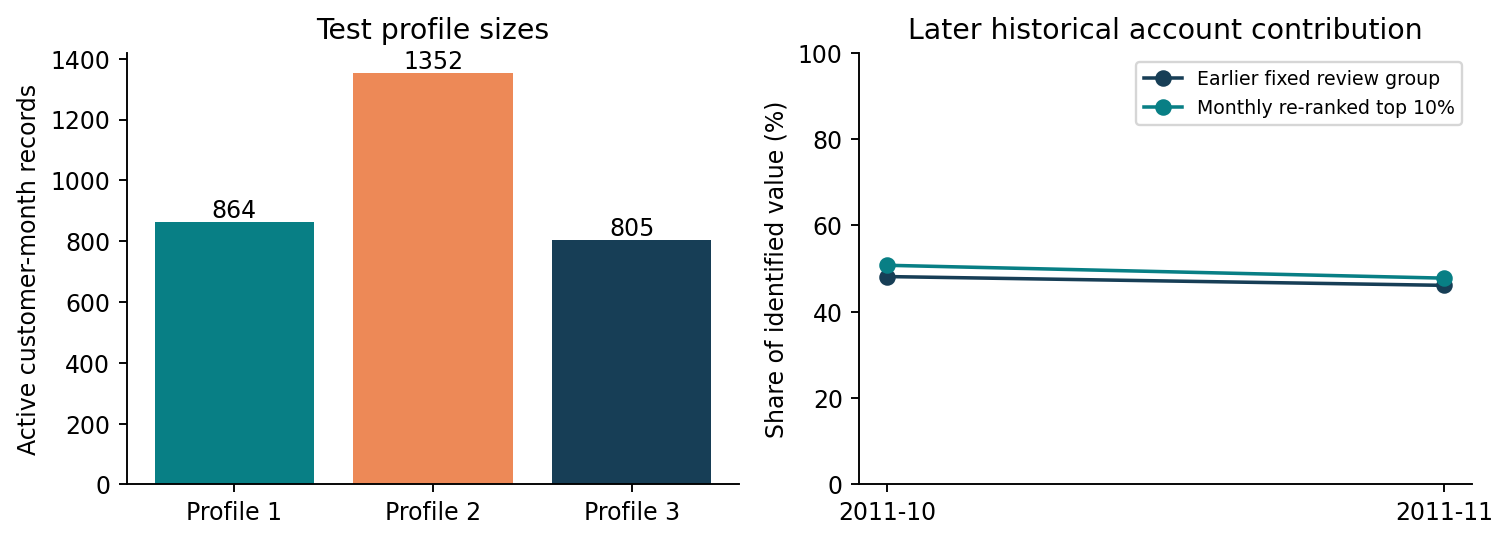

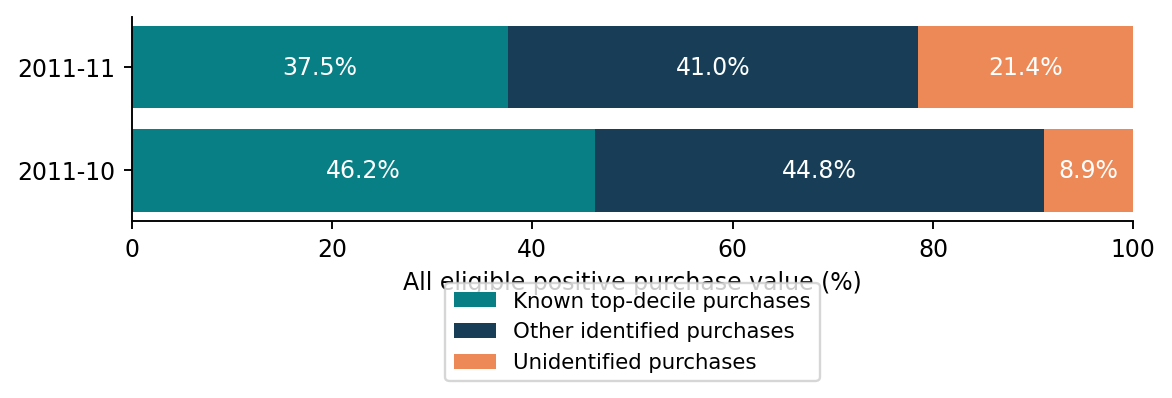

In [8]:
def make_figures(test, profiles, stability, bridge, output):
    output=Path(output); output.mkdir(parents=True,exist_ok=True)
    plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'savefig.dpi':170})
    palette={'Profile 1':'#087F85','Profile 2':'#ED8957','Profile 3':'#173E56',
             'Lower value':'#90C5BD','Middle value':'#39718A','Higher value':'#ED8957'}
    fig,axes=plt.subplots(1,2,figsize=(10,3.6),sharex=True,sharey=True)
    for ax,col,title in zip(axes,['reference','cluster'],['Reference: training value cutoffs','KMeans: frozen training profiles']):
        for group,g in test.groupby(col):
            ax.scatter(g.invoices,g.mean_invoice_value_gbp,s=13,alpha=.35,label=group,color=palette[group])
        ax.set(xscale='log',yscale='log',xlabel='Eligible invoices per active ID-month',title=title)
        ax.legend(fontsize=8);ax.grid(alpha=.15)
    axes[0].set_ylabel('Mean eligible invoice value (GBP; log scale)')
    fig.tight_layout();fig.savefig(output/'reference_vs_profiles.png',bbox_inches='tight');plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(9,3.3))
    g=profiles.loc[profiles.method.eq('KMeans')]
    axes[0].bar(g['group'],g.records,color=[palette[x] for x in g['group']])
    for i,v in enumerate(g.records):axes[0].text(i,v+15,str(v),ha='center')
    axes[0].set(ylabel='Active customer-month records',title='Test profile sizes')
    axes[1].plot(stability.month,stability.frozen_group_known_value_pct,marker='o',label='Earlier fixed review group',color='#173E56')
    axes[1].plot(stability.month,stability.reranked_K10_pct,marker='o',label='Monthly re-ranked top 10%',color='#087F85')
    axes[1].set(ylim=(0,100),ylabel='Share of identified value (%)',title='Later historical account contribution')
    axes[1].legend(fontsize=8);fig.tight_layout();fig.savefig(output/'sizes_and_stability.png',bbox_inches='tight');plt.close(fig)
    fig,ax=plt.subplots(figsize=(7,2.7));bottom=np.zeros(len(bridge))
    for column,color in zip(bridge.columns[1:],['#087F85','#173E56','#ED8957']):
        vals=bridge[column].to_numpy();ax.barh(bridge.month,vals,left=bottom,color=color,label=column)
        for i,(v,left) in enumerate(zip(vals,bottom)):ax.text(left+v/2,i,f'{v:.1f}%',ha='center',va='center',color='white',fontsize=10)
        bottom+=vals
    ax.set(xlim=(0,100),xlabel='All eligible positive purchase value (%)');ax.legend(loc='upper center',bbox_to_anchor=(.5,-.25),ncol=1,fontsize=9)
    fig.tight_layout();fig.savefig(output/'identified_and_unidentified_value.png',bbox_inches='tight');plt.close(fig)
    return [output/name for name in ['reference_vs_profiles.png','sizes_and_stability.png','identified_and_unidentified_value.png']]
figure_paths=make_figures(test,test_profiles,stability,value_bridge,OUT)
for path in figure_paths:
    display(Image(filename=str(path)))

## 8. Conclusions, limits and next improvement

**Model verdict: retain this first model for descriptive profiling.** All 2,192 validation and 3,021 test records receive assignments from the unchanged training transform and centers, with three populated groups in both periods. Silhouette is 0.472 in validation and 0.464 in test, compared with 0.300 and 0.289 for the value rule. The small observed difference between validation and test supports a similar level of internal separation in these later records. It is not a statistical stability test, a universal acceptance threshold or an independent prospective validation.

**What remains unvalidated.** The model distinguishes the selected purchase patterns. We have not established whether commercial users find those profiles useful, whether the same structure persists in recent data, or whether acting on them improves outcomes. We retain it as a descriptive aid for analyst review, rather than approve automated customer actions. If the decision only concerns contribution, the simpler value grouping remains sufficient.

**What the model adds.** It decomposes purchase activity into frequency and invoice size, enabling a more specific account review than a total-value tier alone. In the held records, the more frequent profile contributes a large fraction of identified value. This supports examining its invoices and account characteristics; it does not identify profitable or loyal accounts or prove that a campaign will work.

**What the later-period diagnostic adds.** The earlier fixed review group continues to contribute substantial identified value, while its active membership and contribution vary. Coverage worsens in November. The separate unidentified bucket prevents treating the known-ID ranking as the whole business.

**Important limits.** Only purchase-active identified records enter clustering. IDs recur and can change profile across months. KMeans imposes three Euclidean groups, the feature choice omits other behaviors, and the historical source has provisional item codes and unverified operational completeness. Both log/scaling choices and repeated monthly participation affect distances. Validation/test periods were seen in earlier EDA. Internal silhouette scores do not measure action effects, future performance or market representativeness.

**Next improvement.** Obtain recent transactions with verified customer linkage, apply the frozen grouping to complete comparable months and review profiles with a commercial stakeholder before considering an intervention. Reliable linking of the unidentified bucket would expand coverage; a campaign's effect would require separate evaluation.

## 9. Contributions, AI use and references

**Contribution note:** Moisés provided our project context, source data/previous deliveries, updated course brief and W2 feedback. **Assigned defense preparation:** for our final review, Moisés will check preparation, fitting and validation; Ignacia will check profiles, the reference comparison and business interpretation. These are planned review responsibilities. Both of us will review the interpretation and prepare to explain the whole submitted route.

**AI assistance:** OpenAI Codex assisted with code, notebook/brief/presentation drafts and automated consistency checks. Verification includes input hashing, W2 result reproduction, source/partition conservation, identical comparison records, training-only fit invariance and a complete fresh-kernel run. These are automated checks, not an assertion that a particular student personally performed them. The team remains responsible for reviewing the interpretation and defending each decision. No instructor feedback or completed individual contribution is invented.

**References**
1. Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository. DOI: https://doi.org/10.24432/C5BW33. CC BY 4.0. Source/dictionary: https://archive.ics.uci.edu/dataset/352/online-retail.
2. scikit-learn 1.5.2. [KMeans](https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.KMeans.html), [StandardScaler](https://scikit-learn.org/1.5/modules/generated/sklearn.preprocessing.StandardScaler.html), [silhouette_score](https://scikit-learn.org/1.5/modules/generated/sklearn.metrics.silhouette_score.html).
3. Fontecilla, T. (2026). *C2: Train and explain your first model*, updated IIB423T-1 brief supplied by the team. Course notebooks *Class 04: EDA to Supervised/Unsupervised* and *Validation, Leakage and Reproducible Pipelines* informed the method and train-only preparation. Teacher materials are not included in the ZIP.

The following cell exports the same numerical evidence used in the brief and presentation. Generated CSV/JSON/image files are development outputs and are **not** included in the submission ZIP.

In [9]:
all_metrics=pd.concat([validation_metrics,test_metrics],ignore_index=True)
tables={'quality':quality,'row_flow':row_flow,'source_partitions':source_partitions,'model_partitions':model_partitions,
        'validation_profiles':validation_profiles,'test_profiles':test_profiles,'metrics':all_metrics,
        'validation_gate':gate,'test_cross':test_cross.reset_index(),'stability':stability,'value_bridge':value_bridge}
for name,table in tables.items():table.to_csv(OUT/f'{name}.csv',index=False)
results={'annual_W2_reproduction':annual,'frozen_model':frozen,'metrics':all_metrics.to_dict(orient='records'),
         'source_partitions':source_partitions.to_dict(orient='records'),'model_partitions':model_partitions.to_dict(orient='records'),
         'test_profiles':test_profiles.to_dict(orient='records'),'test_cross':test_cross.reset_index().to_dict(orient='records'),
         'stability':stability.to_dict(orient='records'),'value_bridge':value_bridge.to_dict(orient='records'),
         'validation_gate':gate.to_dict(orient='records'),'source':source_info,'customer_overlap':overlap_rows}
(OUT/'C2_results.json').write_text(json.dumps(results,indent=2,ensure_ascii=False)+chr(10),encoding='utf-8')
print('Final results exported. Notebook code and saved outputs are the primary executable evidence.')

Final results exported. Notebook code and saved outputs are the primary executable evidence.


## 10. Individual defense checkpoints

These prompts support preparation; each student should answer independently in their own words. No live AI assistance is allowed in the defense.

1. **What is a modeling row?** An active identified customer-month. A source line is an invoice item entry, and multiple lines/invoices aggregate into that monthly row. The 3,021 test rows represent 2,405 distinct active IDs.
2. **Why frequency and average invoice value?** Their product is monthly value. The two inputs distinguish more invoices from larger invoices without adding a redundant total-value feature. Neither includes future purchases.
3. **What does KMeans learn?** Three centers in the standardized log-feature space. It iteratively assigns each record to the nearest center and updates centers to reduce within-group squared distance. Labels are arbitrary; our profile numbering uses only training medians. Three is a manageable first choice, not a demonstrated optimum.
4. **Why log1p and StandardScaler?** Logarithms reduce large ranges. Standardization puts two different units on a comparable scale. Both affect the meaning of similarity. Only training records determine the means, scales and centers; later transforms do not refit them.
5. **How is the reference fair?** It uses training monthly-value percentiles and assigns every validation/test record with fixed cutoffs. The model and reference compare on identical rows. A later higher-value share of 12.6% is compatible with a training 90th percentile cutoff.
6. **What does silhouette 0.464 mean?** It is the average of (b − a) / max(a, b), where a is a record's mean distance to its own group and b is its nearest other group's mean distance. It describes internal separation in these features. It is not 46.4% accuracy, a probability, external label validation or proof of better actions.
7. **What did the model add?** The 380 higher-value test ID-months split between 124 in Profile 2 and 256 in Profile 3. A similar value tier can contain different frequency/invoice-size patterns. Profile 3 contributes 55.0% of identified test value, with a different denominator from all eligible value.
8. **What remains uncertain?** Missing IDs exclude some value from profiling, recurrent IDs create dependence, KMeans/feature choices impose structure, and the period is historical with prior full-case exposure. An absent purchase is not proven churn. Reviewing accounts and ID capture is supported; profit, loyalty or campaign effects are not established. Recent linked transactions and stakeholder review are the next improvement.
9. **Does the model work?** For the descriptive task, we retain it: all held records receive one of three interpretable profiles, and test silhouette 0.464 is close to validation 0.472 and above the value rule's 0.289 on those same test records. Commercial usefulness, permanent customer types and action effects remain unvalidated. No arbitrary silhouette cutoff or predictive accuracy is claimed.